# Face Liveness Detection: phân biệt khuôn mặt thật (REAL) và giả (FAKE)

Hệ thống nhận diện **qua camera theo thời gian thực**, phân biệt:
* **REAL**: khuôn mặt người thật xuất hiện trước camera.
* **FAKE**: khuôn mặt giả qua **ảnh** hoặc **video phát lại** (màn hình, điện thoại).

**Các phương pháp dùng trong notebook**

| Phương pháp | Công cụ | Vai trò |
|---|---|---|
| Phát hiện khuôn mặt | MediaPipe Face Landmarker (Google) | Tìm mặt, lấy hộp mặt |
| Chớp mắt | MediaPipe (blendshape `eyeBlink`) | Hiển thị số lần chớp |
| Xoay đầu | MediaPipe (ma trận xoay → yaw/pitch/roll) | Hiển thị hướng đầu |
| Chuyển động khuôn mặt | Độ dịch chuyển landmark | Hiển thị mức chuyển động |
| Khóa ánh sáng | Cổng kiểm tra độ sáng + khóa phơi sáng camera | Không kết luận khi ánh sáng xấu |
| **MiniVision** | MiniFASNet (Silent-Face-Anti-Spoofing) | **Quyết định REAL/FAKE** |

**Đánh giá:** trên dataset công khai **NUAA Photograph Imposter Database** (15 người, ảnh thật và ảnh in). **Ngưỡng tốt nhất chọn trên tập train**, Accuracy, Confusion Matrix, ROC, AUC **đo trên tập test** (theo cách chia sẵn của dataset). Mọi số liệu tính khi chạy notebook, không gõ tay.

**Cách chạy:** chạy các cell từ trên xuống. Cell cuối (mục 9) mở camera, nhấn **q** hoặc **ESC** để thoát.

## 1. Kiểm tra tính khả thi

**Google ML Kit trong Python?** Không dùng được. ML Kit chỉ có SDK cho **Android/iOS**, không có bản Python chính thức.
**Cách tích hợp (đã chọn):** dùng **MediaPipe** của Google, có Python SDK và cho các tín hiệu tương đương:

| ML Kit | Thay bằng (MediaPipe Face Landmarker) |
|---|---|
| Face detection + box | 478 landmark → hộp mặt |
| `eyeOpenProbability` | blendshape `eyeBlinkLeft/Right` (nhắm = 1, mở = 0) |
| `headEulerAngleY/X/Z` | yaw/pitch/roll tính từ ma trận xoay khuôn mặt |
| Face tracking | chế độ `VIDEO` + độ dịch chuyển landmark |

Nếu bắt buộc dùng ML Kit thật: viết app Android/iOS dùng ML Kit rồi gửi kết quả về server Python.

**MiniVision: dùng được.** [Silent-Face-Anti-Spoofing](https://github.com/minivision-ai/Silent-Face-Anti-Spoofing) (Apache-2.0) có model **MiniFASNet** huấn luyện sẵn trên PyTorch. Đây là mô hình nhìn **một khung hình** và đọc kết cấu ảnh (vân màn hình, phản chiếu, mép ảnh in), không cần người dùng làm động tác.

**"Khóa ánh sáng"** (đề bài không nói rõ, notebook hiểu như sau, bạn chỉnh nếu hiểu khác):
1. **Cổng ánh sáng:** đo độ sáng vùng mặt; quá tối, cháy sáng hoặc thiếu tương phản thì hệ thống báo `BAD LIGHT` và **không kết luận** (vì MiniVision kém tin cậy).
2. **Khóa phơi sáng camera** (phím `l` ở realtime): tắt tự động phơi sáng để camera không tự bù sáng làm đổi điều kiện. *Thực nghiệm, phụ thuộc driver camera, chưa kiểm chứng.*

**Điều không được khẳng định:** chớp mắt và xoay đầu **không đủ** để chứng minh người thật, vì một video phát lại của người đang chớp mắt/quay đầu vẫn vượt qua kiểm tra đó. Vì vậy **quyết định REAL/FAKE dựa vào MiniVision**; chớp mắt, hướng đầu, chuyển động chỉ để hiển thị.

## 2. Cài đặt, import và cấu hình
Cell tự cài thư viện còn thiếu. Khuyến nghị dùng môi trường ảo riêng (`python -m venv .venv`, rồi `pip install -r requirements.txt`).

In [1]:
# ===== (1) Tự cài các thư viện còn thiếu =====
import importlib.util, subprocess, sys

REQUIRED = {"mediapipe": "mediapipe", "torch": "torch", "numpy": "numpy", "sklearn": "scikit-learn",
            "matplotlib": "matplotlib", "pandas": "pandas", "requests": "requests", "tqdm": "tqdm"}   # {tên import: tên pip}
missing = [pip for mod, pip in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
    print("Đã cài", missing, "- nếu import bên dưới lỗi, hãy Restart kernel rồi chạy lại.")

# ===== (2) Import =====
import os, json, time, math, warnings, platform
from pathlib import Path
from collections import deque
from dataclasses import dataclass

import numpy as np, pandas as pd, cv2, torch, requests
import torch.nn.functional as F
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks.python import vision as mp_vision, BaseOptions
from IPython.display import display
from tqdm.auto import tqdm

warnings.filterwarnings("ignore")
os.environ.setdefault("GLOG_minloglevel", "2")            # giảm log rác của MediaPipe

# ===== (3) Thư mục làm việc =====
ROOT    = Path.cwd()                 # thư mục chứa notebook
MODELS  = ROOT / "models"            # model MiniVision + MediaPipe
DATA    = ROOT / "data"              # dataset NUAA (data/raw, giải nén từ data/dataset.zip)
RESULTS = ROOT / "results"           # kết quả: điểm từng ảnh, threshold
for d in (MODELS, DATA, RESULTS): d.mkdir(exist_ok=True)

# Có mở camera ở mục 9 không? Đặt biến môi trường LIVENESS_NO_CAMERA=1 để bỏ qua (chạy tự động).
RUN_CAMERA = os.environ.get("LIVENESS_NO_CAMERA") != "1"
FORCE_RECOMPUTE = False              # True = tính lại điểm thay vì đọc cache trong results/

C_REAL, C_FAKE = "#2a78d6", "#eb6834"                      # màu REAL (xanh), FAKE (cam)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})

print("Python", platform.python_version(), "| OpenCV", cv2.__version__, "| PyTorch", torch.__version__, "| MediaPipe", mp.__version__)

Python 3.10.11 | OpenCV 5.0.0 | PyTorch 2.14.1+cpu | MediaPipe 1.2.2


## 3. Tải model và đọc dataset

* **Model MiniVision**: file code `MiniFASNet.py` (định nghĩa mạng) và 2 file trọng số `.pth`, tải từ GitHub của MiniVision (cố định theo commit).
* **Model MediaPipe**: `face_landmarker.task`.
* **Dataset**: **NUAA Photograph Imposter Database** (bản trên Kaggle), file `data/dataset.zip`. Nếu chưa có thư mục `data/raw/`, cell dưới tự giải nén.

```
data/raw/
├── ClientRaw/0001 ... 0015/     ảnh người thật trước webcam        (nhãn REAL)
├── ImposterRaw/0001 ... 0016/   ảnh chụp lại ảnh in của người đó   (nhãn FAKE, loại "print")
├── client_train_raw.txt   imposter_train_raw.txt    danh sách ảnh tập TRAIN
└── client_test_raw.txt    imposter_test_raw.txt     danh sách ảnh tập TEST
```

* Mỗi thư mục con là **1 người**. Ảnh là các khung hình rời của một lần quay (chuỗi). Tên file `0001_00_00_01_125.jpg`: 4 phần đầu xác định **chuỗi**, phần cuối là **số thứ tự khung** trong chuỗi.
* **Train / test** đọc từ 4 file `.txt` (cách chia gốc của dataset). Ngưỡng chọn trên train, kết quả báo cáo trên test, để không "chấm bài bằng đáp án".

**Hạn chế (đọc trước khi xem kết quả):** NUAA chỉ có **tấn công bằng ảnh in**, **không có video phát lại hay màn hình**; ảnh 640×480 từ webcam cũ, 15 người. Một số người có mặt ở cả train và test (khác buổi quay).

In [2]:
# ===== Hàm tải file (bỏ qua nếu file đã có) =====
def download(url, dest):
    """Tải 1 file về `dest`. Bỏ qua nếu đã tồn tại."""
    dest = Path(dest); dest.parent.mkdir(parents=True, exist_ok=True)
    if dest.exists() and dest.stat().st_size > 0:
        return dest
    tmp = dest.with_name(dest.name + ".part")                 # ghi vào file tạm, xong mới đổi tên (tránh file hỏng)
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        with open(tmp, "wb") as f:
            for chunk in r.iter_content(1 << 20):
                f.write(chunk)
    tmp.replace(dest)
    return dest

# ===== Tải model MiniVision (Apache-2.0) =====
MV_COMMIT = "b6d5f04ad78778917853b25c778acef6d5626d15"       # cố định commit để kết quả tái lập được
MV = f"https://raw.githubusercontent.com/minivision-ai/Silent-Face-Anti-Spoofing/{MV_COMMIT}"
download(f"{MV}/src/model_lib/MiniFASNet.py",                                 MODELS / "MiniFASNet.py")
download(f"{MV}/resources/anti_spoof_models/2.7_80x80_MiniFASNetV2.pth",      MODELS / "2.7_80x80_MiniFASNetV2.pth")
download(f"{MV}/resources/anti_spoof_models/4_0_0_80x80_MiniFASNetV1SE.pth",  MODELS / "4_0_0_80x80_MiniFASNetV1SE.pth")

# ===== Tải model MediaPipe Face Landmarker (Google) =====
download("https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task",
         MODELS / "face_landmarker.task")
print("Model:", sorted(p.name for p in MODELS.iterdir() if p.suffix in (".pth", ".py", ".task")))

Model: ['2.7_80x80_MiniFASNetV2.pth', '4_0_0_80x80_MiniFASNetV1SE.pth', 'MiniFASNet.py', 'face_landmarker.task']


In [3]:
# ===== (1) Giải nén dataset.zip nếu chưa có thư mục data/raw =====
import zipfile
DATASET_ZIP, DATASET_DIR = DATA / "dataset.zip", DATA / "raw"
if not DATASET_DIR.exists():
    assert DATASET_ZIP.exists(), f"Không thấy {DATASET_DIR} hoặc {DATASET_ZIP}"
    print("Đang giải nén", DATASET_ZIP.name, "...")
    zipfile.ZipFile(DATASET_ZIP).extractall(DATA)            # zip chứa sẵn thư mục raw/

FRAME_STEP = 1      # 1 = dùng mọi ảnh. Máy chậm: đặt 2, 3... để lấy 1 ảnh trong mỗi FRAME_STEP ảnh của mỗi chuỗi

# ===== (2) Lập bảng manifest từ 4 file danh sách train/test, mỗi dòng 1 ảnh =====
rows = []
for txt in sorted(DATASET_DIR.glob("*_raw.txt")):            # client_train_raw.txt, imposter_test_raw.txt, ...
    split = "train" if "_train_" in txt.name else "test"
    for line in txt.read_text().split():
        p = DATASET_DIR / line.split("/raw/", 1)[1]           # bỏ tiền tố đường dẫn Kaggle '/kaggle/input/.../raw/'
        cls, a = p.parts[-3], p.stem.split("_")               # cls = ClientRaw | ImposterRaw; a = các phần của tên file
        label = 1 if cls == "ClientRaw" else 0                # ClientRaw = người thật (REAL), ImposterRaw = ảnh in (FAKE)
        rows.append(dict(path=str(p), group=f"{cls}/{p.stem}",               # group: mã duy nhất của 1 ảnh
                         seq=f"{cls}/{'_'.join(a[:4])}", frame_no=int(a[4]),  # chuỗi quay + số thứ tự khung
                         subject=a[0], split=split, label=label, kind="real" if label else "print"))
meta = pd.DataFrame(rows).sort_values(["seq", "frame_no"]).reset_index(drop=True)
meta = meta[meta.groupby("seq").cumcount() % FRAME_STEP == 0].reset_index(drop=True)
assert meta.group.is_unique and all(Path(p).exists() for p in meta.path), "Danh sách .txt không khớp với ảnh trong thư mục"

# ===== (3) Tóm tắt: số ảnh, số chuỗi, số người theo train/test và nhãn =====
summary = meta.groupby(["split", "label"]).agg(số_ảnh=("path", "size"), số_chuỗi=("seq", "nunique"),
                                               số_người=("subject", "nunique")).reset_index()
summary.insert(1, "nhãn", summary.label.map({1: "REAL", 0: "FAKE"}))
display(summary.drop(columns="label").sort_values("split", ascending=False))
both = sorted(set(meta[meta.split == "train"].subject) & set(meta[meta.split == "test"].subject))
print(f"Tổng {len(meta)} ảnh | người có ở cả train và test (khác buổi quay): {both}")

,split,nhãn,số_ảnh,số_chuỗi,số_người
2,train,FAKE,1748,45,9
3,train,REAL,1743,16,9
0,test,FAKE,5761,73,15
1,test,REAL,3362,9,9


Tổng 12614 ảnh | người có ở cả train và test (khác buổi quay): ['0001', '0002', '0003', '0004', '0005', '0006', '0007', '0008', '0009']


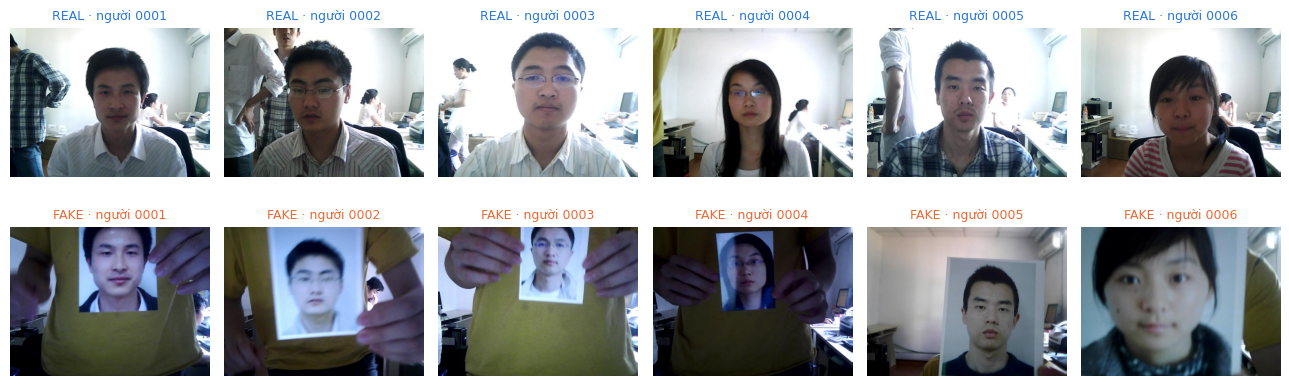

In [4]:
# ===== Xem thử dataset: 6 ảnh REAL và 6 ảnh FAKE của các người khác nhau =====
fig, axes = plt.subplots(2, 6, figsize=(13, 4.4))
for row_ax, label in zip(axes, [1, 0]):
    pick = meta[meta.label == label].groupby("subject").nth(0).head(6)       # ảnh đầu tiên của 6 người đầu
    for ax, r in zip(row_ax, pick.itertuples()):
        ax.imshow(cv2.cvtColor(cv2.imread(r.path), cv2.COLOR_BGR2RGB))
        ax.set_title(f"{'REAL' if label else 'FAKE'} · người {r.subject}", color=C_REAL if label else C_FAKE, fontsize=9)
    for ax in row_ax: ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Các module lõi

### 4.1 MiniVision: chấm điểm "thật" từ một khung hình
Cách làm theo repo gốc: cắt vùng quanh mặt (mở rộng ×2.7 và ×4.0), resize về 80×80, đưa vào 2 mạng, lấy `softmax` rồi **trung bình**. Mạng có 3 lớp đầu ra, **lớp số 1 = người thật**. Kết quả `p_real` ∈ [0, 1].

In [5]:
sys.path.insert(0, str(MODELS))
from MiniFASNet import MiniFASNetV2, MiniFASNetV1SE         # định nghĩa mạng (file MiniVision vừa tải)

def load_minifas(fname, ctor):
    """Tạo mạng và nạp trọng số .pth (strict: lỗi ngay nếu sai khóa, không bỏ sót trọng số nào)."""
    net = ctor(conv6_kernel=(5, 5), num_classes=3)           # ảnh vào 80x80 -> conv6_kernel = 5
    sd = torch.load(MODELS / fname, map_location="cpu")
    sd = {k.replace("module.", ""): v for k, v in sd.items()}        # bỏ tiền tố do huấn luyện bằng DataParallel
    for a in ("fc1", "bn1", "fc2", "bn2"):                           # tên khối SE trong file .pth khác trong code
        sd = {k.replace("se_" + a, "se_module." + a): v for k, v in sd.items()}
    net.load_state_dict(sd)
    return net.eval()                                        # chế độ suy luận (tắt dropout)

class MiniVisionFAS:
    """MiniVision anti-spoofing. predict(ảnh_BGR, box) -> p_real (xác suất là người thật)."""
    def __init__(self):
        self.nets = [(2.7, load_minifas("2.7_80x80_MiniFASNetV2.pth", MiniFASNetV2)),      # (tỉ lệ cắt, mạng)
                     (4.0, load_minifas("4_0_0_80x80_MiniFASNetV1SE.pth", MiniFASNetV1SE))]

    @staticmethod
    def crop(img, box, scale, out=80):
        """Cắt vùng quanh mặt, mở rộng `scale` lần, resize về out x out (giống repo gốc)."""
        x, y, w, h = box
        H, W = img.shape[:2]
        scale = min((H - 1) / h, (W - 1) / w, scale) # không vượt quá kích thước ảnh
        nw, nh, cx, cy = w * scale, h * scale, x + w / 2, y + h / 2
        x1, y1 = max(0, cx - nw / 2), max(0, cy - nh / 2)
        x2, y2 = min(W - 1, cx + nw / 2), min(H - 1, cy + nh / 2)
        return cv2.resize(img[int(y1):int(y2) + 1, int(x1):int(x2) + 1], (out, out))

    @torch.no_grad()
    def predict(self, img_bgr, box):
        probs = []
        for scale, net in self.nets:
            c = self.crop(img_bgr, box, scale)
            t = torch.from_numpy(c.transpose(2, 0, 1).astype(np.float32)).unsqueeze(0) # BGR, giá trị 0..255 như repo
            probs.append(F.softmax(net(t), dim=1)[0].numpy())
        p = np.mean(probs, axis=0) # trung bình 2 mạng
        return float(p[1]) # p[1] = "người thật"

fas = MiniVisionFAS()
print("Đã nạp MiniVision (2 model).")

Đã nạp MiniVision (2 model).


### 4.2 Phát hiện mặt, chớp mắt, xoay đầu, chuyển động, ánh sáng
* **`FaceAnalyzer`**: MediaPipe Face Landmarker → hộp mặt, 478 landmark, điểm nhắm mắt, góc yaw/pitch/roll.
* **`BlinkDetector`**: đếm chớp mắt; mắt nhắm khi `blink ≥ 0.5`, mở lại khi `< 0.3`, và nhắm trong 40–700 ms thì tính 1 cái chớp.
* **`MotionTracker`**: mức chuyển động khuôn mặt giữa 2 khung hình (đã trừ tịnh tiến, chia cho bề rộng mặt).
* **`light_stats` (cổng ánh sáng)**: đo độ sáng, tương phản, tỉ lệ cháy sáng vùng mặt. Các ngưỡng là **lựa chọn thiết kế**, chưa tinh chỉnh.
* Quy ước góc: **yaw > 0** = quay sang phải ảnh, **pitch > 0** = cúi xuống.

In [6]:
def resize_max(img, max_side):
    """Thu nhỏ ảnh sao cho cạnh dài <= max_side (ảnh 4K sẽ rất chậm nếu không thu nhỏ)."""
    s = max_side / max(img.shape[:2])
    return img if s >= 1 else cv2.resize(img, None, fx=s, fy=s, interpolation=cv2.INTER_AREA)

@dataclass
class FaceObs:
    """Kết quả phân tích 1 khuôn mặt trong 1 khung hình."""
    box: tuple        # (x, y, w, h) hộp mặt
    lm: np.ndarray    # (478, 2) landmark, đơn vị pixel
    blink: float      # 0 = mắt mở ... 1 = nhắm
    yaw: float        # độ; > 0 = quay sang phải ảnh
    pitch: float      # độ; > 0 = cúi xuống
    roll: float       # độ; nghiêng đầu

class FaceAnalyzer:
    """Phát hiện + theo dõi khuôn mặt bằng MediaPipe (thay cho ML Kit Face Detection)."""
    def __init__(self, video_mode=False):
        opts = mp_vision.FaceLandmarkerOptions(
            base_options=BaseOptions(model_asset_path=str(MODELS / "face_landmarker.task")),
            running_mode=mp_vision.RunningMode.VIDEO if video_mode else mp_vision.RunningMode.IMAGE,
            num_faces=1,
            output_face_blendshapes=True,                    # cần cho điểm chớp mắt
            output_facial_transformation_matrixes=True)      # cần cho góc xoay đầu
        self.model, self.video_mode, self._last_ts = mp_vision.FaceLandmarker.create_from_options(opts), video_mode, -1

    def process(self, img_bgr, ts_ms=None):
        """Phân tích 1 khung hình. Trả về FaceObs, hoặc None nếu không thấy mặt."""
        mp_img = mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
        if self.video_mode:                                  # chế độ video: có theo dõi mặt giữa các khung
            ts = max(int(ts_ms if ts_ms is not None else time.time() * 1000), self._last_ts + 1)   # timestamp phải tăng dần
            self._last_ts = ts
            res = self.model.detect_for_video(mp_img, ts)
        else:
            res = self.model.detect(mp_img)
        if not res.face_landmarks:
            return None
        # --- hộp mặt: lấy từ min/max của các landmark ---
        H, W = img_bgr.shape[:2]
        lm = np.array([[p.x * W, p.y * H] for p in res.face_landmarks[0]])
        (x0, y0), (x1, y1) = lm.min(0), lm.max(0)
        # --- điểm nhắm mắt: trung bình blendshape mắt trái/phải ---
        bs = {c.category_name: c.score for c in res.face_blendshapes[0]}
        blink = 0.5 * (bs.get("eyeBlinkLeft", 0.0) + bs.get("eyeBlinkRight", 0.0))
        # --- góc xoay đầu: tách từ ma trận xoay 3x3 ---
        R = np.array(res.facial_transformation_matrixes[0])[:3, :3]
        R = R / np.linalg.norm(R, axis=0)                    # bỏ hệ số scale
        yaw   = math.degrees(math.atan2(R[0, 2], R[2, 2]))
        pitch = math.degrees(math.asin(np.clip(-R[1, 2], -1, 1)))
        roll  = math.degrees(math.atan2(R[1, 0], R[1, 1]))
        return FaceObs((x0, y0, x1 - x0, y1 - y0), lm, blink, yaw, pitch, roll)

class BlinkDetector:
    """Đếm chớp mắt từ chuỗi điểm `blink` theo thời gian (ms). Dùng 2 ngưỡng (đóng/mở) để không đếm trùng."""
    def __init__(self, close_th=0.5, open_th=0.3, min_ms=40, max_ms=700):
        self.close_th, self.open_th, self.min_ms, self.max_ms = close_th, open_th, min_ms, max_ms
        self.reset()
    def reset(self):
        self.closed, self.t_close, self.count = False, 0, 0
    def update(self, blink, ts_ms):
        if not self.closed and blink >= self.close_th:       # bắt đầu nhắm mắt
            self.closed, self.t_close = True, ts_ms
        elif self.closed and blink < self.open_th:           # mở mắt lại
            self.closed = False
            if self.min_ms <= ts_ms - self.t_close <= self.max_ms:
                self.count += 1                              # nhắm đủ ngắn mới tính là 1 cái chớp (không phải nhắm lâu)
        return self.count

class MotionTracker:
    """Chuyển động khuôn mặt giữa 2 khung hình liên tiếp (% bề rộng mặt), đã loại tịnh tiến và phóng to/thu nhỏ."""
    def __init__(self): self.prev = None
    def reset(self): self.prev = None
    def update(self, lm):
        face_w = np.linalg.norm(lm[454] - lm[234]) + 1e-6    # bề rộng mặt (landmark 2 bên má)
        norm = (lm - lm.mean(0)) / face_w                    # chuẩn hóa: bỏ vị trí và kích thước
        move = 0.0 if self.prev is None else float(np.linalg.norm(norm - self.prev, axis=1).mean() * 100)
        self.prev = norm
        return move

# ---- Cổng ánh sáng: ngưỡng do thiết kế chọn, KHÔNG tinh chỉnh trên dataset ----
LIGHT_MIN, LIGHT_MAX, LIGHT_MAX_SAT, LIGHT_MIN_STD = 55, 205, 0.10, 15

def light_stats(img_bgr, box):
    """Đo ánh sáng vùng mặt (60% giữa hộp mặt). light_ok = False nếu quá tối / cháy sáng / thiếu tương phản."""
    x, y, w, h = box
    H, W = img_bgr.shape[:2]
    roi = img_bgr[int(max(0, y + .2 * h)):int(min(H, y + .8 * h)), int(max(0, x + .2 * w)):int(min(W, x + .8 * w))]
    if roi.size == 0:
        return dict(luma=np.nan, contrast=np.nan, sat=np.nan, light_ok=False)
    Y = cv2.cvtColor(roi, cv2.COLOR_BGR2YCrCb)[..., 0].astype(np.float32)    # kênh Y = độ sáng
    luma, contrast, sat = float(Y.mean()), float(Y.std()), float((Y > 235).mean())
    ok = LIGHT_MIN <= luma <= LIGHT_MAX and sat < LIGHT_MAX_SAT and contrast >= LIGHT_MIN_STD
    return dict(luma=luma, contrast=contrast, sat=sat, light_ok=bool(ok))

print("Đã định nghĩa FaceAnalyzer, BlinkDetector, MotionTracker, light_stats.")

Đã định nghĩa FaceAnalyzer, BlinkDetector, MotionTracker, light_stats.


## 5. Chạy hệ thống trên dataset (chấm điểm từng ảnh)
* Mỗi ảnh: tìm mặt (MediaPipe) → `p_real` từ MiniVision → đo ánh sáng, độ mở mắt, góc đầu.
* Ảnh được xử lý **theo thứ tự trong từng chuỗi**, nên đo được thêm **chuyển động khuôn mặt** giữa 2 ảnh liên tiếp (cột `motion`; ảnh đầu chuỗi để trống).
* Ảnh **không thấy mặt** được báo riêng và **không** đưa vào đánh giá.
* Kết quả lưu `results/frame_scores.csv`. Lần sau đọc lại cache (mất vài chục phút nếu chạy lại hết khoảng 12.600 ảnh trên CPU).

In [7]:
CACHE_FRAMES = RESULTS / "frame_scores.csv"

def score_dataset(meta):
    """Chấm điểm từng ảnh (meta đã sắp xếp theo chuỗi, số thứ tự khung). Trả về DataFrame: mỗi dòng 1 ảnh."""
    an, motion, out, prev_seq = FaceAnalyzer(video_mode=False), MotionTracker(), [], None   # ảnh rời -> IMAGE mode
    for r in tqdm(list(meta.itertuples()), desc="Chấm điểm"):
        if r.seq != prev_seq:                                # sang chuỗi mới -> đo chuyển động lại từ đầu
            motion.reset(); prev_seq = r.seq
        fr = resize_max(cv2.imread(r.path), 1280)
        obs = an.process(fr)
        row = dict(group=r.group, seq=r.seq, subject=r.subject, frame_no=r.frame_no, split=r.split,
                   label=r.label, kind=r.kind, found=obs is not None)
        if obs is not None:                                  # thấy mặt -> chấm điểm
            first = motion.prev is None                      # ảnh đầu chuỗi: chưa có ảnh trước để so
            move = motion.update(obs.lm)
            row.update(p_real=fas.predict(fr, obs.box), face_ratio=obs.box[2] / fr.shape[1],
                       eye_open=1 - obs.blink, yaw=obs.yaw, pitch=obs.pitch, roll=obs.roll,
                       motion=np.nan if first else move, **light_stats(fr, obs.box))
        out.append(row)
    return pd.DataFrame(out)

if CACHE_FRAMES.exists() and not FORCE_RECOMPUTE and set(pd.read_csv(CACHE_FRAMES).group) == set(meta.group):
    frames = pd.read_csv(CACHE_FRAMES, dtype={"subject": str}); print("Đọc cache:", CACHE_FRAMES.name)
else:
    t0 = time.time(); frames = score_dataset(meta); frames.to_csv(CACHE_FRAMES, index=False)
    print(f"Xong trong {time.time() - t0:.0f}s, đã lưu {CACHE_FRAMES.name}")

# Thống kê: số ảnh, số ảnh thấy mặt, số ảnh đạt cổng ánh sáng theo train/test và nhãn
det = frames.groupby(["split", "label"]).agg(số_ảnh=("found", "size"), thấy_mặt=("found", "sum"),
                                             ánh_sáng_ok=("light_ok", lambda v: int((v == True).sum()))).reset_index()
det.insert(1, "nhãn", det.label.map({1: "REAL", 0: "FAKE"}))
display(det.drop(columns="label").sort_values("split", ascending=False))

Đọc cache: frame_scores.csv


,split,nhãn,số_ảnh,thấy_mặt,ánh_sáng_ok
2,train,FAKE,1748,1741,1734
3,train,REAL,1743,1743,999
0,test,FAKE,5761,5760,5405
1,test,REAL,3362,3362,626


## 6. Chớp mắt, xoay đầu, chuyển động
* Dùng lại kết quả mục 5 (không chạy lại MediaPipe), gộp theo **chuỗi**: mỗi chuỗi giống một đoạn video ngắn.
* **Số lần chớp mắt**: đưa độ nhắm mắt của các ảnh trong chuỗi (theo thứ tự) vào `BlinkDetector`, mốc thời gian = số thứ tự khung ÷ 20 khung/giây (**giả định** tốc độ quay gốc của NUAA). Các ảnh trong dataset cách nhau khoảng 3–5 khung (khoảng 150–250 ms), nên **cú chớp ngắn có thể bị bỏ sót**: số đếm chỉ là gần đúng.
* **Biên độ xoay đầu** = yaw lớn nhất − yaw nhỏ nhất trong chuỗi. **Chuyển động** = trung bình cột `motion`.
* Mỗi tín hiệu kèm **AUC khi dùng riêng nó** (0.5 = không phân biệt được; càng xa 0.5 càng phân biệt).

In [8]:
from sklearn.metrics import roc_auc_score

NUAA_FPS = 20                                                 # giả định: NUAA quay ~20 khung/giây (~500 khung/chuỗi)
ev_all = frames[frames.found]                                 # chỉ các ảnh có thấy mặt

def seq_cues(g):
    """Tín hiệu theo thời gian của 1 chuỗi: số lần chớp, biên độ xoay đầu, chuyển động trung bình."""
    b = BlinkDetector()
    for eye_open, fn in zip(g.eye_open, g.frame_no):
        b.update(1 - eye_open, fn * 1000 / NUAA_FPS)          # độ nhắm mắt + mốc thời gian (ms)
    return pd.Series(dict(số_ảnh=len(g), số_chớp=b.count, biên_độ_yaw=np.ptp(g.yaw), chuyển_động=g.motion.mean()))

seqs = ev_all.groupby(["seq", "label"]).apply(seq_cues, include_groups=False).reset_index()

# ===== Bảng trung bình theo nhãn + AUC của từng tín hiệu (mức chuỗi) =====
tab = seqs.groupby("label")[["số_ảnh", "số_chớp", "biên_độ_yaw", "chuyển_động"]].mean()
tab.insert(0, "số_chuỗi", seqs.groupby("label").size())
display(tab.rename(index={1: "REAL", 0: "FAKE"}).round(2))
for name, col in [("số lần chớp mắt", "số_chớp"), ("biên độ xoay đầu", "biên_độ_yaw"), ("chuyển động khuôn mặt", "chuyển_động")]:
    ok = seqs[col].notna()                                    # bỏ chuỗi quá ngắn (không đo được chuyển động)
    print(f"AUC (mức chuỗi) nếu chỉ dùng {name:22s} = {roc_auc_score(seqs.label[ok], seqs[col][ok]):.3f}")
print(f"AUC (mức ảnh)  nếu chỉ dùng độ mở mắt             = {roc_auc_score(ev_all.label, ev_all.eye_open):.3f}")

,số_chuỗi,số_ảnh,số_chớp,biên_độ_yaw,chuyển_động
label,,,,,
FAKE,118,63.57,0.00,10.88,1.84
REAL,25,204.20,2.84,11.73,0.61


AUC (mức chuỗi) nếu chỉ dùng số lần chớp mắt        = 0.860
AUC (mức chuỗi) nếu chỉ dùng biên độ xoay đầu       = 0.533
AUC (mức chuỗi) nếu chỉ dùng chuyển động khuôn mặt  = 0.106
AUC (mức ảnh)  nếu chỉ dùng độ mở mắt             = 0.443


**Cách đọc:**
* **Chớp mắt** tách REAL/FAKE khá tốt trên NUAA: người thật có chớp, ảnh in thì không. Nhưng đó chỉ vì tấn công ở đây là **ảnh in tĩnh**. Một **video phát lại** người đang chớp mắt sẽ vượt qua kiểm tra này, và NUAA không có loại tấn công đó để kiểm chứng.
* **Chuyển động** có AUC **dưới 0.5**, nghĩa là **FAKE chuyển động nhiều hơn REAL**: ảnh in bị cầm tay rung, uốn cong, còn người thật ngồi yên. Vậy "có chuyển động" **không** có nghĩa là người thật.
* **Biên độ xoay đầu** có AUC gần 0.5: không phân biệt được.

Vì vậy **quyết định REAL/FAKE dựa vào MiniVision**; chớp mắt, xoay đầu, chuyển động chỉ để hiển thị.

## 7. Đánh giá: Accuracy, Confusion Matrix, ROC, AUC, ngưỡng tốt nhất

**Quy ước:** lớp dương = **REAL**; điểm = `p_real`; dự đoán REAL nếu `p_real ≥ threshold`.

| Thuật ngữ | Ý nghĩa |
|---|---|
| **FAR** | tỉ lệ FAKE bị chấp nhận nhầm là REAL (nguy hiểm nhất) |
| **FRR** | tỉ lệ REAL bị từ chối nhầm |
| **Balanced accuracy** | trung bình tỉ lệ đúng của hai lớp |

**Quy trình (quan trọng):**
1. **Chọn ngưỡng tốt nhất trên tập TRAIN** theo **Youden's J** (ngưỡng làm TPR − FPR lớn nhất).
2. **Giữ nguyên ngưỡng đó, đo mọi chỉ số trên tập TEST.** Đây là con số để báo cáo.
3. Để tham khảo, in thêm ngưỡng Youden tính thẳng trên test ("chấm bài bằng đáp án", lạc quan), để thấy mức chênh.

Tập test có số FAKE nhiều hơn REAL, nên **Accuracy bị kéo về lớp đông hơn** (cell in ra mốc "luôn đoán lớp đông nhất" để so sánh). Hãy xem thêm Balanced accuracy, FAR và FRR.

In [9]:
from sklearn.metrics import roc_curve, roc_auc_score

ev = frames[frames.found].reset_index(drop=True)             # chỉ dùng ảnh có thấy mặt
tr, te = ev[ev.split == "train"], ev[ev.split == "test"].reset_index(drop=True)
y_tr, s_tr = tr.label.values, tr.p_real.values               # TRAIN: chỉ để chọn ngưỡng
y, s = te.label.values, te.p_real.values                     # TEST: để báo cáo kết quả

def metrics_at(y, s, t):
    """Các chỉ số khi dự đoán REAL nếu điểm >= t."""
    pred = (s >= t).astype(int)
    TP, FN = int(((pred == 1) & (y == 1)).sum()), int(((pred == 0) & (y == 1)).sum())
    FP, TN = int(((pred == 1) & (y == 0)).sum()), int(((pred == 0) & (y == 0)).sum())
    tpr, tnr = TP / max(TP + FN, 1), TN / max(TN + FP, 1)
    return dict(threshold=t, accuracy=(TP + TN) / len(y), balanced_acc=(tpr + tnr) / 2,
                FAR=1 - tnr, FRR=1 - tpr, TP=TP, FN=FN, FP=FP, TN=TN)

# ---- (1) Chọn ngưỡng tốt nhất trên TRAIN (Youden) ----
fpr_tr, tpr_tr, thr_tr = roc_curve(y_tr, s_tr, drop_intermediate=False)
THRESHOLD = float(thr_tr[np.argmax(tpr_tr - fpr_tr)])        # ngưỡng làm TPR - FPR lớn nhất trên train
auc_tr = roc_auc_score(y_tr, s_tr)

# ---- (2) ROC, AUC trên TEST ----
fpr, tpr, thr = roc_curve(y, s, drop_intermediate=False)
auc = roc_auc_score(y, s)
thr_oracle = float(thr[np.argmax(tpr - fpr)])                # Youden tính thẳng trên test: CHỈ để tham khảo

# ---- (3) Khoảng tin cậy 95% của AUC test: bootstrap theo NGƯỜI (ảnh cùng người rất giống nhau, không độc lập) ----
rng, subj = np.random.default_rng(0), te.subject.values
idx_of = {g: np.where(subj == g)[0] for g in np.unique(subj)}
boot = []
for _ in range(1000):
    pick = rng.choice(list(idx_of), len(idx_of), replace=True)       # chọn lại ngẫu nhiên các người (có lặp)
    ii = np.concatenate([idx_of[g] for g in pick])
    if len(np.unique(y[ii])) == 2: boot.append(roc_auc_score(y[ii], s[ii]))
auc_lo, auc_hi = np.percentile(boot, [2.5, 97.5])

# ---- (4) Bảng kết quả trên TEST ----
table = pd.DataFrame({"Ngưỡng 0.5 (mặc định)": metrics_at(y, s, 0.5),
                      "Ngưỡng chọn trên TRAIN (báo cáo)": metrics_at(y, s, THRESHOLD),
                      "Youden trên TEST (tham khảo, lạc quan)": metrics_at(y, s, thr_oracle)}).T
print(f"TRAIN: {len(y_tr)} ảnh | AUC train = {auc_tr:.4f} | ngưỡng tốt nhất (Youden trên train) = {THRESHOLD:.4f}")
print(f"TEST : {len(y)} ảnh (REAL = {int((y == 1).sum())}, FAKE = {int((y == 0).sum())}) của {len(idx_of)} người")
print(f"Accuracy nếu luôn đoán lớp đông nhất = {max((y == 0).mean(), (y == 1).mean()):.3f}  <- mốc so sánh cho Accuracy")
print(f"AUC test = {auc:.4f}  (khoảng tin cậy 95%: {auc_lo:.3f} - {auc_hi:.3f})")
display(table.round(4))

# ---- (5) Lỗi theo từng người trên TEST (ở ngưỡng train): người nào khó nhất? ----
per_subj = te.assign(sai=((s >= THRESHOLD).astype(int) != y), lớp=te.label.map({1: "FRR (REAL bị từ chối)", 0: "FAR (FAKE lọt qua)"}))
display(per_subj.pivot_table(index="subject", columns="lớp", values="sai", aggfunc="mean").round(3).T)

# ---- (6) Kiểm tra nhiễu dataset: nếu đặc trưng tầm thường (không phải MiniVision) tự tách được REAL/FAKE
#      thì kết quả có thể bị thổi phồng do cách thu thập dữ liệu ----
print("Kiểm tra nhiễu trên TEST (AUC khi chỉ dùng 1 đặc trưng tầm thường; 0.5 = không phân biệt):")
for name, col in [("kích thước mặt / ảnh", "face_ratio"), ("độ sáng vùng mặt", "luma"), ("độ tương phản", "contrast")]:
    a = roc_auc_score(y, te[col])
    print(f"  {name:22s} AUC = {a:.3f}" + ("   <- CẢNH BÁO: tự nó đã tách gần hết REAL/FAKE" if max(a, 1 - a) >= 0.9 else ""))

# ---- (7) Lưu ngưỡng để realtime dùng ----
(RESULTS / "threshold.json").write_text(json.dumps(
    dict(threshold=THRESHOLD, method="Youden J trên tập train NUAA", auc_train=auc_tr, auc_test=auc,
         auc_test_ci95=[auc_lo, auc_hi], n_train=int(len(y_tr)), n_test=int(len(y))), indent=2))
print("Đã lưu results/threshold.json")

TRAIN: 3484 ảnh | AUC train = 1.0000 | ngưỡng tốt nhất (Youden trên train) = 0.1080
TEST : 9122 ảnh (REAL = 3362, FAKE = 5760) của 16 người
Accuracy nếu luôn đoán lớp đông nhất = 0.631  <- mốc so sánh cho Accuracy
AUC test = 1.0000  (khoảng tin cậy 95%: 1.000 - 1.000)


,threshold,accuracy,balanced_acc,FAR,FRR,TP,FN,FP,TN
Ngưỡng 0.5 (mặc định),0.500,1.0000,1.0000,0.000,0.0,3362.0,0.0,0.0,5760.0
Ngưỡng chọn trên TRAIN (báo cáo),0.108,0.9993,0.9995,0.001,0.0,3362.0,0.0,6.0,5754.0
"Youden trên TEST (tham khảo, lạc quan)",0.649,1.0000,1.0000,0.000,0.0,3362.0,0.0,0.0,5760.0


subject,0001,0002,0003,0004,0005,0006,0007,0008,0009,0010,0011,0012,0013,0014,0015,0016
lớp,,,,,,,,,,,,,,,,
FAR (FAKE lọt qua),0.0,0.0,0.0,0.0,0.005,0.0,0.0,0.0,0.0,0.004,0.0,0.005,NaN,0.002,0.0,0.0
FRR (REAL bị từ chối),NaN,NaN,NaN,0.0,NaN,0.0,0.0,NaN,NaN,0.000,0.0,0.000,0.0,0.000,0.0,NaN


Kiểm tra nhiễu trên TEST (AUC khi chỉ dùng 1 đặc trưng tầm thường; 0.5 = không phân biệt):
  kích thước mặt / ảnh   AUC = 0.367
  độ sáng vùng mặt       AUC = 0.785
  độ tương phản          AUC = 0.786
Đã lưu results/threshold.json


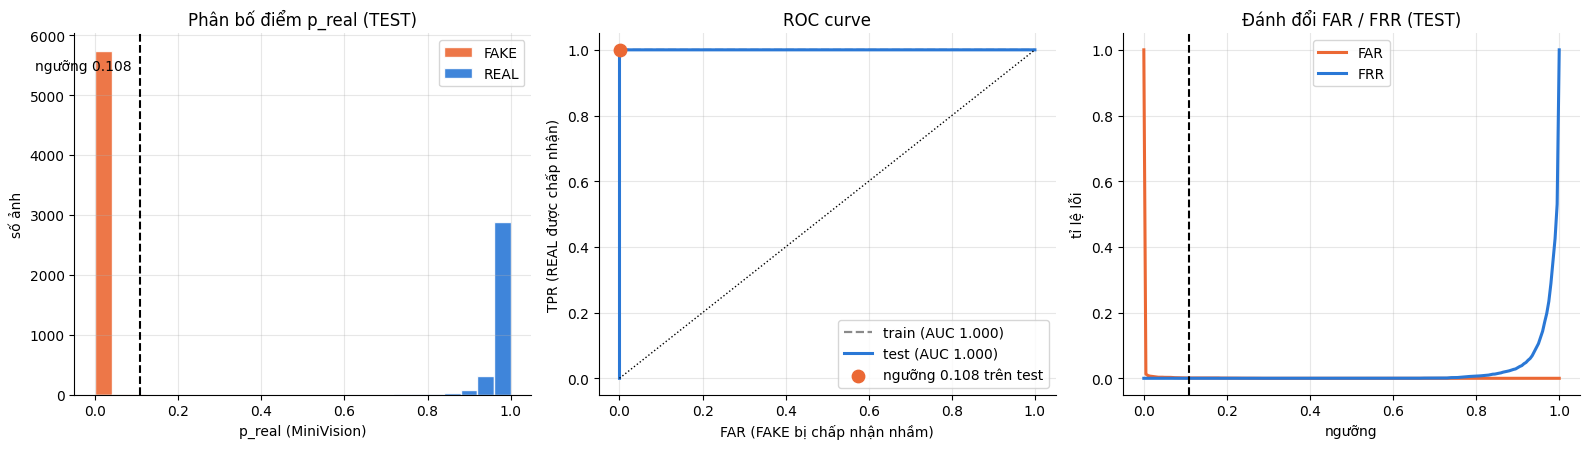

In [10]:
# ===== Biểu đồ trên TEST: phân bố điểm, ROC (kèm ROC train để so sánh), đánh đổi FAR/FRR =====
m = metrics_at(y, s, THRESHOLD)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))

# (1) Phân bố điểm p_real của hai lớp: hai cột càng tách nhau càng tốt
bins = np.linspace(0, 1, 26)
ax[0].hist(s[y == 0], bins, color=C_FAKE, alpha=.9, label="FAKE", edgecolor="white")
ax[0].hist(s[y == 1], bins, color=C_REAL, alpha=.9, label="REAL", edgecolor="white")
ax[0].axvline(THRESHOLD, color="k", ls="--"); ax[0].text(THRESHOLD - 0.02, ax[0].get_ylim()[1] * .9, f"ngưỡng {THRESHOLD:.3f}", ha="right")
ax[0].set(title="Phân bố điểm p_real (TEST)", xlabel="p_real (MiniVision)", ylabel="số ảnh"); ax[0].legend()

# (2) Đường ROC: càng gần góc trên-trái càng tốt; chấm cam = ngưỡng chọn trên train
ax[1].plot(fpr_tr, tpr_tr, color="#8a8a8a", lw=1.6, ls="--", label=f"train (AUC {auc_tr:.3f})")
ax[1].plot(fpr, tpr, color=C_REAL, lw=2.2, label=f"test (AUC {auc:.3f})"); ax[1].plot([0, 1], [0, 1], "k:", lw=1)
ax[1].scatter([m["FAR"]], [1 - m["FRR"]], s=80, color=C_FAKE, zorder=5, label=f"ngưỡng {THRESHOLD:.3f} trên test")
ax[1].set(title="ROC curve", xlabel="FAR (FAKE bị chấp nhận nhầm)", ylabel="TPR (REAL được chấp nhận)"); ax[1].legend(loc="lower right")

# (3) Đánh đổi FAR / FRR theo ngưỡng: tăng ngưỡng thì FAR giảm nhưng FRR tăng
ts = np.linspace(0, 1, 201)
ax[2].plot(ts, [metrics_at(y, s, t)["FAR"] for t in ts], color=C_FAKE, lw=2.2, label="FAR")
ax[2].plot(ts, [metrics_at(y, s, t)["FRR"] for t in ts], color=C_REAL, lw=2.2, label="FRR")
ax[2].axvline(THRESHOLD, color="k", ls="--")
ax[2].set(title="Đánh đổi FAR / FRR (TEST)", xlabel="ngưỡng", ylabel="tỉ lệ lỗi"); ax[2].legend()
plt.tight_layout(); plt.show()

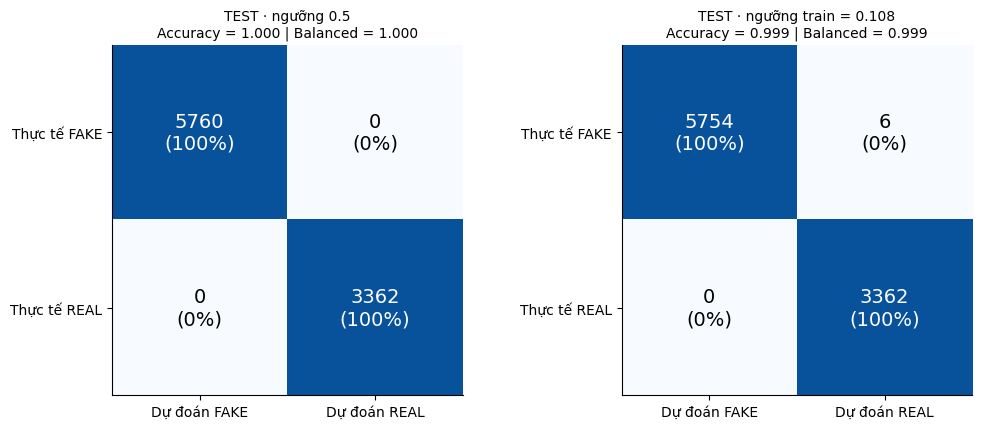

Mức chuỗi (TEST): 82/82 chuỗi đúng | REAL 9/9 | FAKE 73/73


In [11]:
# ===== Confusion matrix trên TEST: ngưỡng mặc định 0.5 và ngưỡng chọn trên train =====
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.4))
for a, (name, t) in zip(axes, [("TEST · ngưỡng 0.5", 0.5), (f"TEST · ngưỡng train = {THRESHOLD:.3f}", THRESHOLD)]):
    mm = metrics_at(y, s, t)
    cm = np.array([[mm["TN"], mm["FP"]], [mm["FN"], mm["TP"]]])      # hàng: thực tế FAKE, REAL; cột: dự đoán FAKE, REAL
    pct = cm / cm.sum(1, keepdims=True)                              # tỉ lệ theo từng hàng
    a.imshow(pct, cmap="Blues", vmin=0, vmax=1.15); a.grid(False)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]}\n({pct[i, j]:.0%})", ha="center", va="center", fontsize=14,
                   color="white" if pct[i, j] > .55 else "black")
    a.set_xticks([0, 1], ["Dự đoán FAKE", "Dự đoán REAL"]); a.set_yticks([0, 1], ["Thực tế FAKE", "Thực tế REAL"])
    a.set_title(f"{name}\nAccuracy = {mm['accuracy']:.3f} | Balanced = {mm['balanced_acc']:.3f}", fontsize=10)
plt.tight_layout(); plt.show()

# ===== Mức chuỗi trên TEST: gộp các ảnh của mỗi chuỗi bằng median (giống cách làm mượt ở realtime) =====
sq = te.groupby(["seq", "label"]).p_real.median().reset_index()
sq_ok = (sq.p_real >= THRESHOLD).astype(int) == sq.label
print(f"Mức chuỗi (TEST): {sq_ok.sum()}/{len(sq)} chuỗi đúng | "
      f"REAL {sq_ok[sq.label == 1].sum()}/{(sq.label == 1).sum()} | FAKE {sq_ok[sq.label == 0].sum()}/{(sq.label == 0).sum()}")

## 8. Hệ thống realtime

**Luồng xử lý mỗi khung hình**
1. Đọc camera (lật gương) → thu nhỏ nếu lớn.
2. **MediaPipe** tìm mặt → hộp mặt, chớp mắt, góc đầu, chuyển động.
3. **MiniVision** chấm `p_real` → lấy **median của 15 khung gần nhất** để ổn định.
4. **Cổng ánh sáng:** nếu ánh sáng xấu thì hiện `BAD LIGHT`, không kết luận.
5. **Quyết định:** `REAL` nếu median `p_real ≥ threshold` (đọc từ `results/threshold.json`), ngược lại `FAKE`. Cần ≥ 8 khung trước khi kết luận (`ANALYZING...`).

**Phím tắt:** `q` / `ESC` thoát · `r` reset · `l` khóa/mở khóa phơi sáng camera (thực nghiệm). Bấm nút X của cửa sổ cũng thoát được.

In [12]:
# ===== Bộ máy nhận diện: ghép tracking + MiniVision + làm mượt + cổng ánh sáng =====
def load_threshold(default=0.5):
    """Đọc ngưỡng đã chọn ở mục 7."""
    f = RESULTS / "threshold.json"
    return json.loads(f.read_text())["threshold"] if f.exists() else default

class LivenessEngine:
    """Nhận từng khung hình, trả về trạng thái REAL / FAKE / BAD LIGHT / ANALYZING... / NO FACE."""
    def __init__(self, threshold, smooth_n=15, min_frames=8, max_side=960):
        self.an, self.threshold, self.min_frames, self.max_side = FaceAnalyzer(video_mode=True), threshold, min_frames, max_side
        self.scores = deque(maxlen=smooth_n)               # p_real của các khung gần nhất
        self.blink, self.motion, self.motion_hist = BlinkDetector(), MotionTracker(), deque(maxlen=30)
        self.last_face_ts = 0
    def reset(self):
        self.scores.clear(); self.blink.reset(); self.motion.reset(); self.motion_hist.clear()

    def step(self, frame, ts_ms):
        """Xử lý 1 khung hình. info['frame'] là ảnh (đã thu nhỏ) để vẽ lên."""
        frame = resize_max(frame, self.max_side)
        obs = self.an.process(frame, ts_ms)
        info = dict(frame=frame, status="NO FACE", obs=None, score=None)
        if obs is None:
            if ts_ms - self.last_face_ts > 1000:           # mất mặt quá 1 giây -> xoá lịch sử điểm
                self.scores.clear(); self.motion.reset()
            return info
        self.last_face_ts = ts_ms
        self.scores.append(fas.predict(frame, obs.box))    # MiniVision chấm p_real cho khung này
        light = light_stats(frame, obs.box)                # cổng ánh sáng
        self.motion_hist.append(self.motion.update(obs.lm))
        score = float(np.median(self.scores))              # median chống nhiễu 1 khung lẻ
        if len(self.scores) < self.min_frames: status = "ANALYZING..."     # chưa đủ khung
        elif not light["light_ok"]:            status = "BAD LIGHT"        # ánh sáng xấu -> không kết luận
        else:                                  status = "REAL" if score >= self.threshold else "FAKE"
        info.update(status=status, obs=obs, score=score, light=light, blinks=self.blink.update(obs.blink, ts_ms),
                    eye_open=1 - obs.blink, motion=float(np.mean(self.motion_hist)))
        return info

STATUS_COLOR = {"REAL": (60, 180, 60), "FAKE": (50, 50, 230), "BAD LIGHT": (0, 170, 240),
                "ANALYZING...": (200, 200, 200), "NO FACE": (150, 150, 150)}      # màu BGR

def head_direction(yaw, pitch, yth=12, pth=10):
    """Mô tả hướng đầu bằng chữ (theo ảnh đã lật gương)."""
    h = "RIGHT" if yaw > yth else "LEFT" if yaw < -yth else ""
    v = "DOWN" if pitch > pth else "UP" if pitch < -pth else ""
    return (v + " " + h).strip() or "CENTER"

def draw_overlay(info, thr, fps, ae_locked):
    """Vẽ hộp mặt, nhãn REAL/FAKE, thanh điểm và bảng thông số lên khung hình."""
    img, font = info["frame"].copy(), cv2.FONT_HERSHEY_SIMPLEX
    H, W = img.shape[:2]; col, obs = STATUS_COLOR[info["status"]], info["obs"]
    lines = []
    if obs is None:
        cv2.putText(img, "NO FACE", (20, 40), font, 1.0, col, 2, cv2.LINE_AA)
    else:
        x, y, w, h = map(int, obs.box)
        cv2.rectangle(img, (x, y), (x + w, y + h), col, 2)                                 # hộp mặt
        cv2.putText(img, info["status"], (x, max(25, y - 10)), font, 0.9, col, 2, cv2.LINE_AA)
        by = min(H - 8, y + h + 14)                                                        # thanh điểm; vạch trắng = ngưỡng
        cv2.rectangle(img, (x, by), (x + w, by + 8), (80, 80, 80), -1)
        cv2.rectangle(img, (x, by), (x + int(w * info["score"]), by + 8), col, -1)
        cv2.line(img, (x + int(w * thr), by - 4), (x + int(w * thr), by + 12), (255, 255, 255), 2)
        L = info["light"]
        lines = [f"score {info['score']:.2f} (thr {thr:.2f})", f"blinks {info['blinks']}",
                 f"head {head_direction(obs.yaw, obs.pitch)} (yaw {obs.yaw:+.0f}, pitch {obs.pitch:+.0f})",
                 f"motion {info['motion']:.2f}%", f"light {L['luma']:.0f} {'ok' if L['light_ok'] else 'BAD'}"
                 + ("  [exposure locked]" if ae_locked else "")]
    for i, t in enumerate(lines):                                                          # bảng thông số góc trên trái
        cv2.putText(img, t, (10, 22 + 22 * i), font, 0.55, (0, 0, 0), 3, cv2.LINE_AA)      # viền đen cho dễ đọc
        cv2.putText(img, t, (10, 22 + 22 * i), font, 0.55, (255, 255, 255), 1, cv2.LINE_AA)
    cv2.putText(img, f"{fps:.0f} FPS | q/ESC quit, r reset, l lock exposure", (10, H - 10), font, 0.5, (255, 255, 255), 1, cv2.LINE_AA)
    return img

def set_exposure_lock(cap, lock):
    """Khóa / mở khóa phơi sáng tự động của camera (THỰC NGHIỆM: phụ thuộc driver, chưa kiểm chứng)."""
    if lock:
        cur = cap.get(cv2.CAP_PROP_EXPOSURE)               # đọc mức phơi sáng hiện tại
        cap.set(cv2.CAP_PROP_AUTO_EXPOSURE, 0.25)          # 0.25 = chế độ thủ công (DirectShow)
        cap.set(cv2.CAP_PROP_EXPOSURE, cur)                # giữ nguyên mức đó
    else:
        cap.set(cv2.CAP_PROP_AUTO_EXPOSURE, 0.75)          # 0.75 = tự động

def run_realtime(source=0, threshold=None, show=True, max_seconds=None, save_to=None, win="Face Liveness"):
    """Chạy hệ thống. source=0: webcam; hoặc đường dẫn video. show=False: không mở cửa sổ (kiểm thử).
    Trả về DataFrame ghi lại trạng thái từng khung hình."""
    thr = load_threshold() if threshold is None else threshold
    is_cam = isinstance(source, int)
    cap = cv2.VideoCapture(source, cv2.CAP_DSHOW) if (is_cam and platform.system() == "Windows") else cv2.VideoCapture(source)
    if not cap.isOpened():
        raise RuntimeError(f"Không mở được nguồn video: {source}")
    eng, writer, log = LivenessEngine(thr), None, []
    src_fps = cap.get(cv2.CAP_PROP_FPS) or 30
    t_start = t_prev = time.time(); n, fps, ae_locked = 0, 0.0, False
    try:
        while True:
            ok, frame = cap.read()
            if not ok: break
            if is_cam: frame = cv2.flip(frame, 1)                                # lật gương cho webcam
            ts = int((time.time() - t_start) * 1000) if is_cam else int(n / src_fps * 1000)
            info = eng.step(frame, ts)                                           # <- nhận diện 1 khung hình
            now = time.time(); fps = 0.9 * fps + 0.1 / max(now - t_prev, 1e-6); t_prev = now
            vis = draw_overlay(info, thr, fps, ae_locked)
            log.append(dict(t_ms=ts, status=info["status"], score=info["score"]))
            if save_to is not None:                                              # (tuỳ chọn) lưu video có chú thích
                if writer is None:
                    writer = cv2.VideoWriter(str(save_to), cv2.VideoWriter_fourcc(*"mp4v"), 20, (vis.shape[1], vis.shape[0]))
                writer.write(vis)
            n += 1
            if show:
                cv2.imshow(win, vis)
                key = cv2.waitKey(1) & 0xFF
                if key in (ord("q"), 27): break                                  # q / ESC: thoát
                if key == ord("r"): eng.reset()                                  # r: reset
                if key == ord("l") and is_cam:                                   # l: khóa/mở khóa phơi sáng
                    ae_locked = not ae_locked; set_exposure_lock(cap, ae_locked)
                if cv2.getWindowProperty(win, cv2.WND_PROP_VISIBLE) < 1: break   # bấm nút X
            if max_seconds and time.time() - t_start > max_seconds: break
    finally:
        cap.release()                                                            # luôn trả camera lại cho hệ thống
        if writer is not None: writer.release()
        if show: cv2.destroyAllWindows(); cv2.waitKey(1)
    return pd.DataFrame(log)

print("Sẵn sàng. Ngưỡng đang dùng:", round(load_threshold(), 4))

Sẵn sàng. Ngưỡng đang dùng: 0.108


### 8.1 Kiểm thử pipeline realtime trên các chuỗi TEST (không cần camera)
Mỗi chuỗi của NUAA là các khung hình liên tiếp của một lần quay, nên có thể **giả lập camera**: đưa lần lượt `SEQ_FRAMES` khung đầu của chuỗi vào `LivenessEngine` (MediaPipe chế độ VIDEO, làm mượt bằng median 15 khung, cổng ánh sáng, ngưỡng chọn trên train ở mục 7). Mốc thời gian = số thứ tự khung ÷ 20 khung/giây. Bên dưới là trạng thái cuối cùng của từng chuỗi và vài khung có chú thích giống cửa sổ camera.

Chỉ dùng tập **test**, vì ngưỡng được chọn trên train.

Xử lý 82 chuỗi (tối đa 45 khung/chuỗi) trong 271s


status,ANALYZING...,BAD LIGHT,FAKE,NO FACE,REAL
nhãn,,,,,
FAKE,4,4,58,7,0
REAL,0,6,0,0,3


Đúng 100.0% trên 61 chuỗi có kết luận; 21 chuỗi không kết luận (BAD LIGHT / NO FACE / ANALYZING)


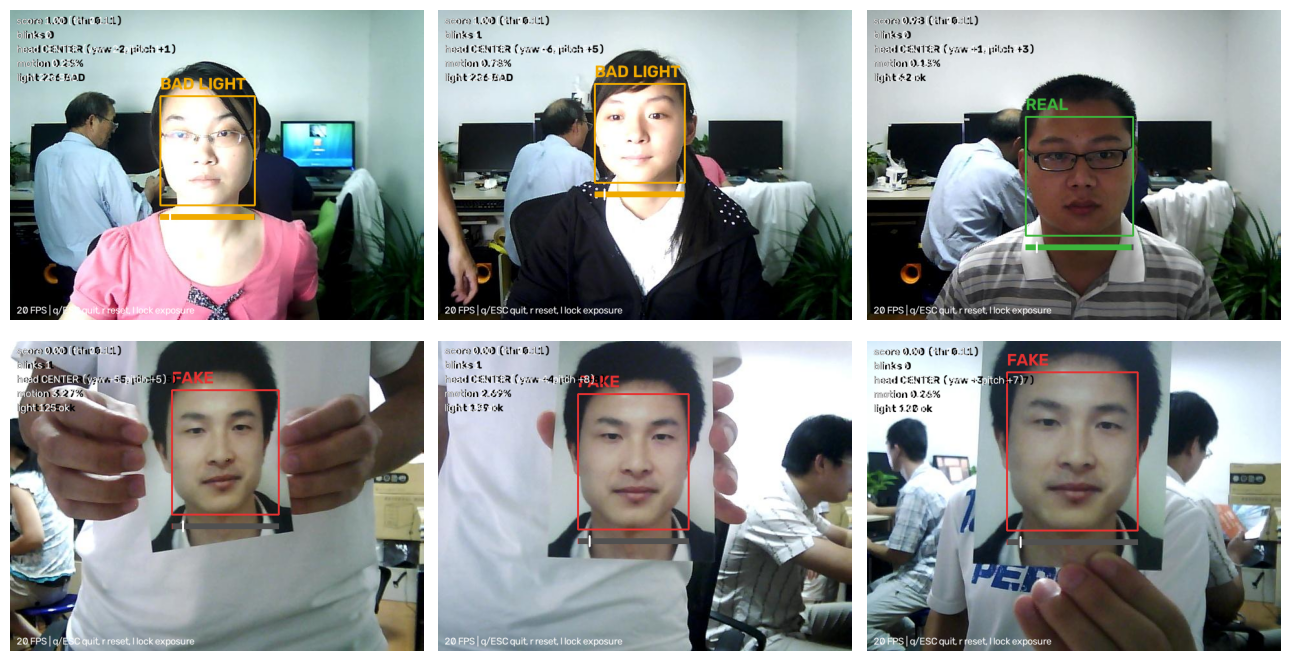

In [13]:
# ===== Giả lập realtime: mỗi chuỗi test là 1 "lần đứng trước camera" =====
SEQ_FRAMES = 45                                               # số khung đầu của mỗi chuỗi đưa vào (đủ > 15 khung làm mượt)
thr, rows, shots = load_threshold(), [], {}
t0 = time.time()
for seq, g in tqdm(list(meta[meta.split == "test"].groupby("seq")), desc="Realtime trên chuỗi test"):
    eng = LivenessEngine(thr)                                 # bộ máy mới cho mỗi chuỗi (không mang lịch sử chuỗi trước)
    for r in g.head(SEQ_FRAMES).itertuples():
        info = eng.step(cv2.imread(r.path), int(r.frame_no * 1000 / NUAA_FPS))   # <- y như 1 khung camera
    rows.append(dict(seq=seq, kind=g.kind.iloc[0], label=g.label.iloc[0], status=info["status"]))
    if info["obs"] is not None and len(shots.setdefault(g.kind.iloc[0], [])) < 3:   # giữ 3 khung mỗi loại để xem
        shots[g.kind.iloc[0]].append(draw_overlay(info, thr, NUAA_FPS, False))
rt = pd.DataFrame(rows)
print(f"Xử lý {len(rt)} chuỗi (tối đa {SEQ_FRAMES} khung/chuỗi) trong {time.time() - t0:.0f}s")

# ===== Bảng trạng thái cuối cùng của mỗi chuỗi =====
display(pd.crosstab(rt.label.map({1: "REAL", 0: "FAKE"}).rename("nhãn"), rt.status))
dec = rt[rt.status.isin(["REAL", "FAKE"])]
print(f"Đúng {((dec.status == 'REAL').astype(int) == dec.label).mean():.1%} trên {len(dec)} chuỗi có kết luận; "
      f"{len(rt) - len(dec)} chuỗi không kết luận (BAD LIGHT / NO FACE / ANALYZING)")

# ===== Xem màn hình realtime: 3 chuỗi mỗi loại =====
fig, axes = plt.subplots(len(shots), 3, figsize=(13, 3.5 * len(shots)))
for row_ax, k in zip(np.atleast_2d(axes), shots):           # mỗi hàng 1 loại (real / print)
    for ax, im in zip(row_ax, shots[k]): ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
    for ax in row_ax: ax.axis("off")
plt.tight_layout(); plt.show()

## 9. Chạy camera realtime
Chạy cell dưới: cửa sổ camera mở ra; nhấn **q** / **ESC** để thoát (hoặc bấm nút X). Nếu muốn dừng từ Jupyter, bấm **Interrupt kernel**: camera vẫn được giải phóng.

Cách thử: (1) nhìn thẳng vào camera → mong đợi `REAL`; (2) đưa ảnh in hoặc ảnh/video trên điện thoại trước camera → mong đợi `FAKE`. Ngưỡng được chọn trên NUAA (webcam cũ 640×480), nên với camera của bạn có thể cần chỉnh: truyền `run_realtime(source=0, threshold=...)`. Hệ thống **không hoàn hảo**, xem số liệu mục 7 và giới hạn mục 10.

In [14]:
if RUN_CAMERA:
    try:
        cam_log = run_realtime(source=0)
        print(f"Đã đóng camera. Số khung hình đã xử lý: {len(cam_log)}")
        print(cam_log.status.value_counts().to_string())
    except cv2.error as e:
        print("Không hiển thị được cửa sổ OpenCV (môi trường không có giao diện?):", e)
    except RuntimeError as e:
        print(e)
else:
    print("Bỏ qua camera (biến môi trường LIVENESS_NO_CAMERA=1).")

Bỏ qua camera (biến môi trường LIVENESS_NO_CAMERA=1).
